# Counterbalancing & Randomisation Checks

Source-file audit, Latin-square block ordering, data dictionary, and consistency checklist.

In [1]:
import re, json, hashlib, os, math, warnings, textwrap, sys
from pathlib import Path
from datetime import datetime
from collections import Counter, OrderedDict
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Import shared JS parsers
NOTEBOOK_CWD = Path.cwd().resolve()
NOTEBOOK_REPO = next((p for p in [NOTEBOOK_CWD, *NOTEBOOK_CWD.parents]
                      if (p / "index.html").is_file() and (p / "static").is_dir()), None)
if NOTEBOOK_REPO is None:
    raise RuntimeError("Open this notebook from within the DroneTask repository.")
sys.path.insert(0, str(NOTEBOOK_REPO / "design_checks" / "scripts"))
from js_import import (load_sources, parse, save_fig, save_html, apply_style,
                        REPO_ROOT, DESIGN_DIR, FIG_DIR, sha256, load_runtime_design)
apply_style()
get_ipython().run_line_magic("matplotlib", "inline")
print("Notebook interpreter", sys.executable)

# ── Load all JS sources ──
stimuli_src = (REPO_ROOT / "static/task/stimuli.js").read_text() if (REPO_ROOT / "static/task/stimuli.js").exists() else ""
memory_src  = (REPO_ROOT / "static/task/memory_task.js").read_text() if (REPO_ROOT / "static/task/memory_task.js").exists() else ""
details_src = (REPO_ROOT / "static/task/stimuli-details.js").read_text() if (REPO_ROOT / "static/task/stimuli-details.js").exists() else ""
trial_src   = (REPO_ROOT / "static/task/trial.js").read_text() if (REPO_ROOT / "static/task/trial.js").exists() else ""
index_src   = (REPO_ROOT / "index.html").read_text() if (REPO_ROOT / "index.html").exists() else ""

# Re-export original helper functions from the shared module
parse_js_flat_array = parse.flat_array
parse_js_2d_array = parse.array_2d
parse_js_string = parse.string
parse_js_string_array = parse.string_array
parse_js_int_pair_array = parse.int_pair_array

# ── Original helper functions that stay local ──
def read_text(relpath):
    p = REPO_ROOT / relpath
    return p.read_text(encoding="utf-8") if p.exists() else None

def pair_in(pair, plist):
    return any(pair[0] == p[0] and pair[1] == p[1] for p in plist)

def styled_table_css(uid="tbl"):
    return textwrap.dedent(f"""\
    <style>
    #{uid} th {{ background:#f3f3f3; color:#222; font-weight:650;
      border:1px solid #d6d6d6; padding:5px 10px; text-align:left; }}
    #{uid} td {{ border:1px solid #e1e1e1; padding:4px 10px;
      font-variant-numeric:tabular-nums; }}
    #{uid} tr:nth-child(even) td {{ background:#fafafa; }}
    #{uid} table {{ border-collapse:collapse; font-size:12px;
      font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Arial,sans-serif; }}
    #{uid} caption {{ caption-side:top; padding:4px 0; color:#444;
      font-size:12px; text-align:left; font-weight:600; }}
    </style>
    """)

# save_html is imported from js_import (category-aware)

print("Setup complete.")

# Evaluate the implementation, including participant assignment and clipping.
runtime_design = load_runtime_design()
runtime_variants = runtime_design['variants']
reference_design = runtime_variants[0]  # reward unshifted; both assignments audited below
print('Condition label version', reference_design['condition_label_version'])


Notebook interpreter /Users/yizj/Desktop/Desktop - beaverjuly/InCogLab/DroneTask/.venv-design/bin/python
Setup complete.


Condition label version trajectory-aligned-v2-20261104


## Source-file and version audit

In [2]:
FILES_TO_CHECK = [
    "static/task/stimuli.js",
    "static/task/memory_task.js",
    "static/task/stimuli-details.js",
    "static/task/trial.js",
    "static/task/latin_square.js",
    "index.html",
]
rows = []
for fp in FILES_TO_CHECK:
    p = REPO_ROOT / fp
    exists = p.exists()
    mtime = datetime.fromtimestamp(p.stat().st_mtime).isoformat() if exists else None
    h = sha256(p)[:16] + "..." if exists else None
    rows.append(dict(file=fp, exists=exists, modified=mtime, sha256_prefix=h))

file_audit = pd.DataFrame(rows)
display(file_audit)
assert file_audit["exists"].all(), "One or more required source files are missing"

stimuli_src = read_text("static/task/stimuli.js")
memory_src  = read_text("static/task/memory_task.js")
details_src = read_text("static/task/stimuli-details.js")
trial_src   = read_text("static/task/trial.js")
index_src   = read_text("index.html")

stim_version = parse_js_string(stimuli_src, "stimuli_version")
print(f"\nstimuli_version = {stim_version!r}")
main_png_paths = parse_js_string_array(stimuli_src, "STIMULUS_IMAGE_POOL") or []
assert len(main_png_paths) == len(set(main_png_paths)) == 200, "Expected 200 unique main stimulus paths"
assert all(path.lower().endswith(".png") and (REPO_ROOT / path).is_file() for path in main_png_paths), "Main PNG stimulus files must exist"
print("\u2713 Confirmed 200 unique existing main PNG stimulus files.")

,file,exists,modified,sha256_prefix
0,static/task/stimuli.js,True,2026-11-04T08:38:04.184512,d4ba319dedb8150a...
1,static/task/memory_task.js,True,2026-11-04T08:59:25.664471,9b39b8e431695596...
2,static/task/stimuli-details.js,True,2026-06-19T06:37:50.318973,f4115cea3efa930c...
3,static/task/trial.js,True,2026-11-04T08:39:21.055073,212f2bc6198b2a09...
4,static/task/latin_square.js,True,2026-11-04T08:38:04.185144,20985835c0737b6c...
5,index.html,True,2026-11-04T08:45:45.661185,18c86f28afdef316...



stimuli_version = 'v15-trajectory-aligned-labels'
✓ Confirmed 200 unique existing main PNG stimulus files.


## Block condition design

The canonical A through D identities and Latin rows stay fixed. High and low labels describe the measured movement and landing noise. Numeric factors are nominal codes, not empirical variances. Both sequence assignments and all four participant groups are executed below.


In [3]:
factors_vol = reference_design['factors_vol']
factors_stc = reference_design['factors_stc']
factors_valence = reference_design['factors_valence']
condition_ids = reference_design['condition_ids']
block_df = pd.DataFrame({
    'canonical_condition': np.arange(1,5),
    'condition_id': condition_ids,
    'valence': factors_valence,
    'vol_code': factors_vol,
    'vol_level': [r['vol_level'] for r in reference_design['metrics']],
    'stc_code': factors_stc,
    'stc_level': [r['stc_level'] for r in reference_design['metrics']],
})
display(block_df)
assert factors_vol == [4,49,4,49] and factors_stc == [64,16,64,16]
assert factors_valence == ['reward','reward','loss','loss']
for variant in runtime_variants:
    for i,row in enumerate(variant['metrics']):
        expected = f"{chr(65+i)}_{row['valence']}_{row['vol_level']}Vol_{row['stc_level']}Stc"
        assert variant['condition_ids'][i] == expected
print('Both trajectory assignments match the saved labels. Factor numbers are nominal design codes, not empirical variances.')


,canonical_condition,condition_id,valence,vol_code,vol_level,stc_code,stc_level
0,1,A_reward_lowVol_highStc,reward,4,low,64,high
1,2,B_reward_highVol_lowStc,reward,49,high,16,low
2,3,C_loss_lowVol_highStc,loss,4,low,64,high
3,4,D_loss_highVol_lowStc,loss,49,high,16,low


Both trajectory assignments match the saved labels. Factor numbers are nominal design codes, not empirical variances.


## Latin-square block-order counterbalancing

The Latin square changes presentation order while each condition remains attached to its canonical identity. The table above reports the current source labels. Both reward shift assignments and all four participant groups are evaluated directly from the JavaScript implementation.


In [4]:
# Also read latin_square.js if available
latin_src = read_text('static/task/latin_square.js') or ''
# Merge into index_src for parsing
combined_src = (latin_src + '\n' + index_src) if latin_src else index_src

# ============================================================
# Latin-square extraction from the implemented source bundle
# ============================================================

import re
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Use existing parsed source variables if they already exist in the notebook.
# Otherwise read directly from repo-local files.
try:
    combined_src
except NameError:
    index_path = REPO_ROOT / "index.html"
    assert index_path.exists(), "index.html not found. Run this notebook from the repo root or set index_path manually."
    combined_src = index_path.read_text(encoding="utf-8")

try:
    stimuli_src
except NameError:
    stimuli_path = REPO_ROOT / "static/task/stimuli.js"
    assert stimuli_path.exists(), "static/task/stimuli.js not found. Run this notebook from the repo root or set stimuli_path manually."
    stimuli_src = stimuli_path.read_text(encoding="utf-8")


def extract_js_array_literal(src, var_name):
    """
    Extract a simple JavaScript array literal assigned as:
      var VAR_NAME = [...];

    Works for the current numeric/string/nested-array design constants.
    """
    pattern = r"var\s+" + re.escape(var_name) + r"\s*=\s*(\[[\s\S]*?\]);"
    m = re.search(pattern, src)

    if not m:
        raise ValueError(f"Could not find JS array variable: {var_name}")

    literal = m.group(1)

    # Current arrays are valid Python literals after normalizing JS strings.
    try:
        return ast.literal_eval(literal)
    except Exception as e:
        raise ValueError(f"Could not parse {var_name}. Extracted literal:\n{literal[:500]}") from e


# Execute current globals after sequence assembly; static literal parsing is not enough.
LATIN_SQUARE_4_EXTRACTED=reference_design['latin_square']
CANONICAL_CONDITION_LABELS_EXTRACTED=reference_design['condition_ids']
FACTORS_VOL_EXTRACTED=reference_design['factors_vol']
FACTORS_STC_EXTRACTED=reference_design['factors_stc']
FACTORS_VALENCE_EXTRACTED=reference_design['factors_valence']
for variant in runtime_variants:
    for group in variant['latin_groups']:
        assert group['order']==LATIN_SQUARE_4_EXTRACTED[group['group']]
        assert group['labels']==[variant['condition_ids'][i] for i in group['order']]
print('Both sequence assignments and all 4 Latin groups preserve canonical identities.')

print("Extracted LATIN_SQUARE_4 from static/task/latin_square.js:")
display(pd.DataFrame(LATIN_SQUARE_4_EXTRACTED, index=[f"group_{i}" for i in range(len(LATIN_SQUARE_4_EXTRACTED))]))

print("Extracted canonical condition labels from static/task/latin_square.js:")
display(pd.DataFrame({
    "canonical_design_idx": range(len(CANONICAL_CONDITION_LABELS_EXTRACTED)),
    "condition_id": CANONICAL_CONDITION_LABELS_EXTRACTED,
    "vol": FACTORS_VOL_EXTRACTED,
    "stc": FACTORS_STC_EXTRACTED,
    "valence": FACTORS_VALENCE_EXTRACTED,
}))

Both sequence assignments and all 4 Latin groups preserve canonical identities.
Extracted LATIN_SQUARE_4 from static/task/latin_square.js:


,0,1,2,3
group_0,0,1,3,2
group_1,1,2,0,3
group_2,2,3,1,0
group_3,3,0,2,1


Extracted canonical condition labels from static/task/latin_square.js:


,canonical_design_idx,condition_id,vol,stc,valence
0,0,A_reward_lowVol_highStc,4,64,reward
1,1,B_reward_highVol_lowStc,49,16,reward
2,2,C_loss_lowVol_highStc,4,64,loss
3,3,D_loss_highVol_lowStc,49,16,loss


In [5]:
# ============================================================
# Latin-square invariant checks
# ============================================================

latin = LATIN_SQUARE_4_EXTRACTED
condition_labels = CANONICAL_CONDITION_LABELS_EXTRACTED

n_groups = len(latin)
n_conditions = len(condition_labels)

assert n_groups == 4, f"Expected 4 Latin-square rows, found {n_groups}."
assert n_conditions == 4, f"Expected 4 canonical conditions, found {n_conditions}."

# Each row must be a permutation of 0, 1, 2, 3.
expected_set = set(range(n_conditions))

for group_idx, row in enumerate(latin):
    assert len(row) == n_conditions, f"Latin group {group_idx} has wrong length: {row}"
    assert set(row) == expected_set, f"Latin group {group_idx} is not a permutation of 0..3: {row}"

# Each displayed block position must contain each canonical condition exactly once across groups.
latin_arr = np.array(latin)

for display_pos in range(n_conditions):
    col = latin_arr[:, display_pos]
    assert set(col) == expected_set, (
        f"Displayed block position {display_pos + 1} does not contain all conditions exactly once: {col}"
    )

print("✓ Each Latin-square row contains all four canonical conditions exactly once.")
print("✓ Each displayed block position receives each canonical condition exactly once across groups.")

# Build long reviewer-facing audit table
latin_rows = []

for group_idx, row in enumerate(latin):
    for display_pos, design_idx in enumerate(row, start=1):
        latin_rows.append(dict(
            latin_square_group=group_idx,
            displayed_block=display_pos,
            canonical_design_idx=design_idx,
            condition_id=condition_labels[design_idx],
            valence=FACTORS_VALENCE_EXTRACTED[design_idx],
            volatility="high" if FACTORS_VOL_EXTRACTED[design_idx] == 49 else "low",
            stochasticity="high" if FACTORS_STC_EXTRACTED[design_idx] == 64 else "low",
            vol_param=FACTORS_VOL_EXTRACTED[design_idx],
            stc_param=FACTORS_STC_EXTRACTED[design_idx],
        ))

latin_df = pd.DataFrame(latin_rows)

display(latin_df)

# Compact matrix view: rows = Latin group, columns = displayed block position
latin_matrix_display = (
    latin_df
    .assign(cell=lambda d: d["condition_id"].str.replace("_", " ", regex=False))
    .pivot(index="latin_square_group", columns="displayed_block", values="cell")
)

display(latin_matrix_display)

# Position-balance check table
position_balance = (
    latin_df
    .groupby(["displayed_block", "condition_id"])
    .size()
    .reset_index(name="count")
)

display(position_balance)

assert (position_balance["count"] == 1).all()
print("✓ Position-balance table confirms count = 1 for every displayed block × condition cell.")

# Canonical labels must remain aligned with their factor arrays.
expected_conditions = [
    (0, "A_reward_lowVol_highStc", 4, 64, "reward"),
    (1, "B_reward_highVol_lowStc", 49, 16, "reward"),
    (2, "C_loss_lowVol_highStc", 4, 64, "loss"),
    (3, "D_loss_highVol_lowStc", 49, 16, "loss"),
]
implemented_conditions = list(zip(
    range(n_conditions), condition_labels, FACTORS_VOL_EXTRACTED,
    FACTORS_STC_EXTRACTED, FACTORS_VALENCE_EXTRACTED
))
assert implemented_conditions == expected_conditions, (
    f"Canonical condition/factor mismatch: {implemented_conditions}"
)
print("✓ Canonical condition labels align with volatility, stochasticity, and valence arrays.")

# Memory trials must inherit canonical identity from the displayed block's
# Latin-square entry, rather than indexing factor arrays by display block.
assert re.search(
    r"var\s+designIdxForBlock\s*=\s*block_order\s*\[\s*blockNum\s*-\s*1\s*\]",
    index_src,
), "Memory timeline does not derive design_idx from block_order"
timeline_bindings = {
    "design_idx": r"design_idx\s*:\s*designIdxForBlock",
    "condition_id": r"condition_id\s*:\s*getCanonicalConditionId\s*\(\s*designIdxForBlock\s*\)",
    "true_vol_param": r"true_vol_param\s*:\s*factors_vol\s*\[\s*designIdxForBlock\s*\]",
    "true_stc_param": r"true_stc_param\s*:\s*factors_stc\s*\[\s*designIdxForBlock\s*\]",
    "valence": r"valence\s*:\s*factors_valence\s*\[\s*designIdxForBlock\s*\]",
}
for field, pattern in timeline_bindings.items():
    assert re.search(pattern, index_src), f"Memory timeline is missing {field} binding"

plugin_parameters = ["design_idx", "condition_id", "true_vol_param", "true_stc_param", "valence"]
for field in plugin_parameters:
    assert re.search(rf"\b{field}\s*:\s*\{{", memory_src), (
        f"memory-task plugin does not declare {field}"
    )

saved_bindings = {
    "display_block": r"display_block\s*:\s*block",
    "design_idx": r"design_idx\s*:\s*_designIdx",
    "canonical_design_idx": r"canonical_design_idx\s*:\s*_designIdx",
    "condition_id": r"condition_id\s*:\s*_conditionId",
    "true_vol_param": r"true_vol_param\s*:\s*_trueVolParam",
    "true_stc_param": r"true_stc_param\s*:\s*_trueStcParam",
    "valence": r"valence\s*:\s*_valence",
    "condition_label_source": r"condition_label_source\s*:\s*_conditionLabelSource",
    "condition_label_mismatch": r"condition_label_mismatch\s*:\s*_conditionLabelMismatch",
}
for field, pattern in saved_bindings.items():
    assert len(re.findall(pattern, memory_src)) >= 2, (
        f"memory-task must save {field} in both completed and skipped trial paths"
    )

for stale_pattern in (
    r"factors_vol\s*\[\s*block\s*-\s*1\s*\]",
    r"factors_stc\s*\[\s*block\s*-\s*1\s*\]",
    r"factors_valence\s*\[\s*block\s*-\s*1\s*\]",
):
    assert not re.search(stale_pattern, memory_src), (
        "Found stale display-block-based condition lookup in memory_task.js"
    )

memory_label_checks_passed = True
print("✓ Memory timeline and plugin preserve Latin-square condition identity in saved data.")

✓ Each Latin-square row contains all four canonical conditions exactly once.
✓ Each displayed block position receives each canonical condition exactly once across groups.


,latin_square_group,displayed_block,canonical_design_idx,condition_id,valence,volatility,stochasticity,vol_param,stc_param
0,0,1,0,A_reward_lowVol_highStc,reward,low,high,4,64
1,0,2,1,B_reward_highVol_lowStc,reward,high,low,49,16
2,0,3,3,D_loss_highVol_lowStc,loss,high,low,49,16
3,0,4,2,C_loss_lowVol_highStc,loss,low,high,4,64
4,1,1,1,B_reward_highVol_lowStc,reward,high,low,49,16
5,1,2,2,C_loss_lowVol_highStc,loss,low,high,4,64
6,1,3,0,A_reward_lowVol_highStc,reward,low,high,4,64
7,1,4,3,D_loss_highVol_lowStc,loss,high,low,49,16
8,2,1,2,C_loss_lowVol_highStc,loss,low,high,4,64
9,2,2,3,D_loss_highVol_lowStc,loss,high,low,49,16


displayed_block,1,2,3,4
latin_square_group,,,,
0,A reward lowVol highStc,B reward highVol lowStc,D loss highVol lowStc,C loss lowVol highStc
1,B reward highVol lowStc,C loss lowVol highStc,A reward lowVol highStc,D loss highVol lowStc
2,C loss lowVol highStc,D loss highVol lowStc,B reward highVol lowStc,A reward lowVol highStc
3,D loss highVol lowStc,A reward lowVol highStc,C loss lowVol highStc,B reward highVol lowStc


,displayed_block,condition_id,count
0,1,A_reward_lowVol_highStc,1
1,1,B_reward_highVol_lowStc,1
2,1,C_loss_lowVol_highStc,1
3,1,D_loss_highVol_lowStc,1
4,2,A_reward_lowVol_highStc,1
5,2,B_reward_highVol_lowStc,1
6,2,C_loss_lowVol_highStc,1
7,2,D_loss_highVol_lowStc,1
8,3,A_reward_lowVol_highStc,1
9,3,B_reward_highVol_lowStc,1


✓ Position-balance table confirms count = 1 for every displayed block × condition cell.
✓ Canonical condition labels align with volatility, stochasticity, and valence arrays.
✓ Memory timeline and plugin preserve Latin-square condition identity in saved data.


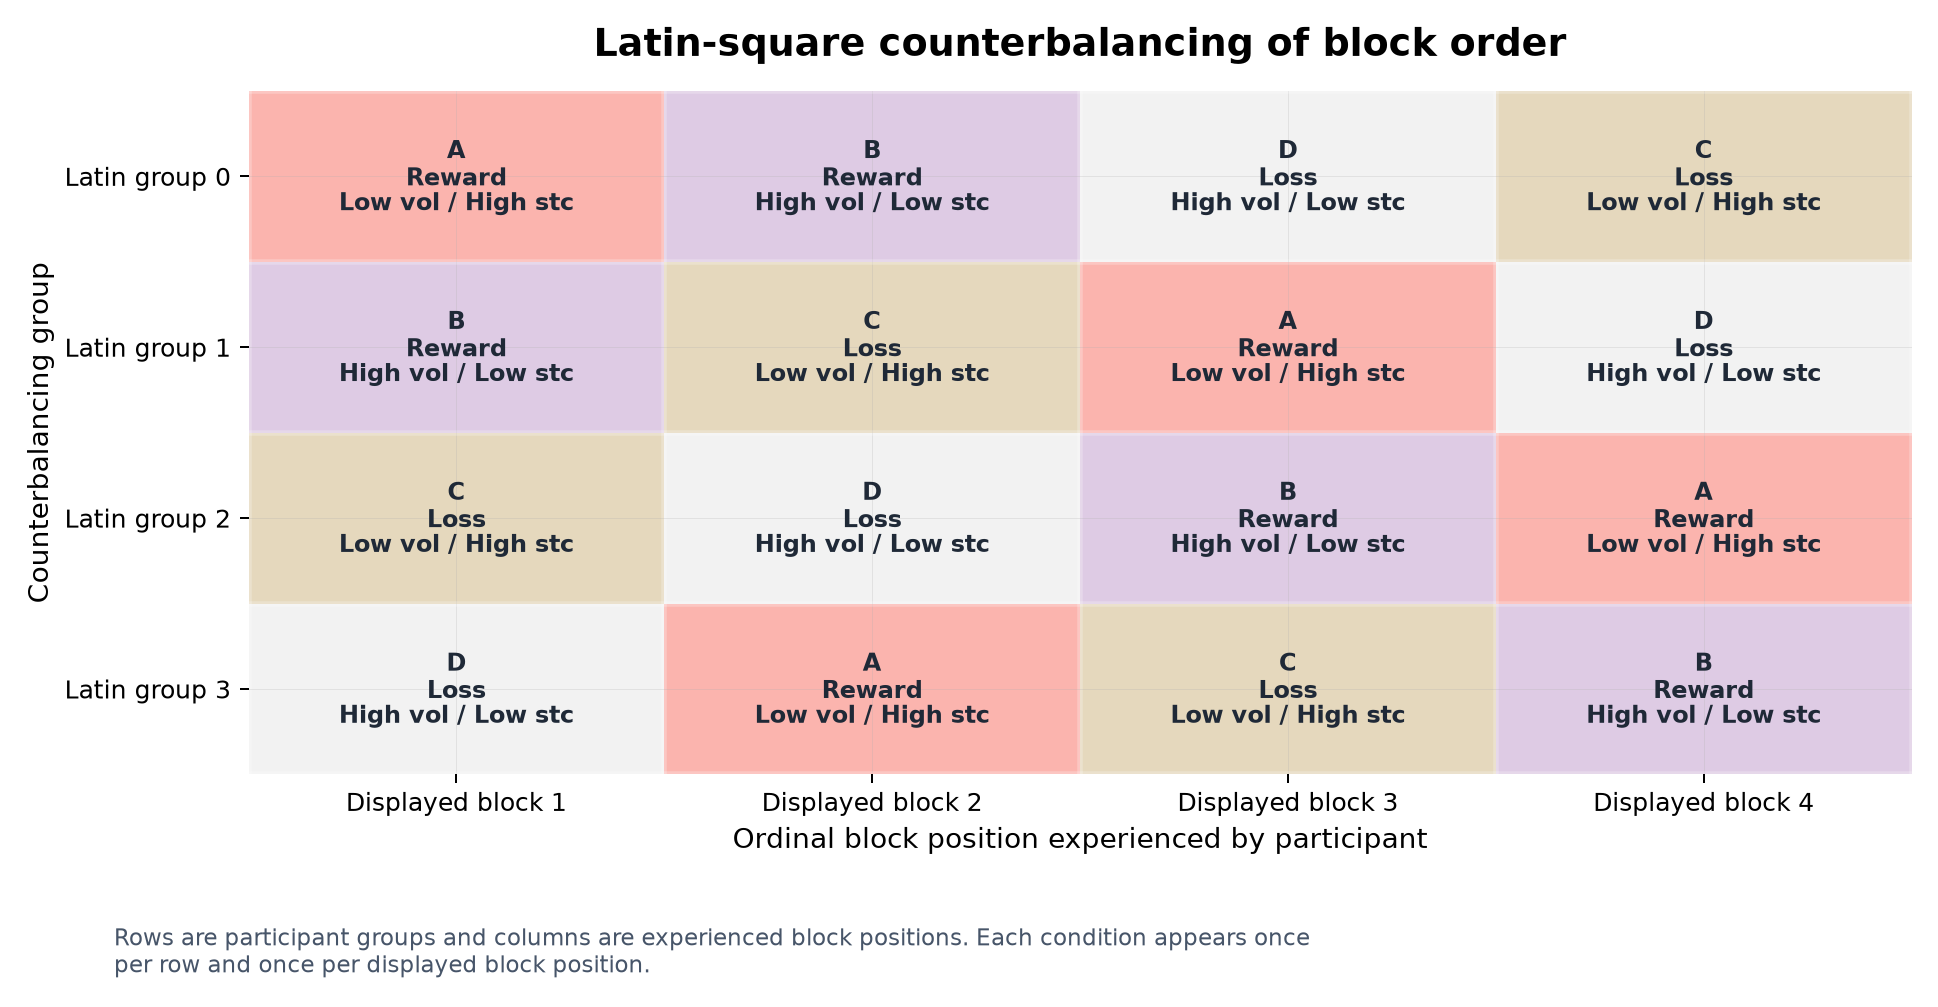

  ✓ counterbalancing/latin_square_block_order.png + .pdf
  ✓ counterbalancing/latin_square_block_order.html
  ✓ counterbalancing/latin_square_block_order.html
✓ Exported latin_square_block_order.html


In [6]:
# ============================================================
# Latin-square visualization
# ============================================================

# Generate labels from executed factors to avoid a second manually maintained mapping.
short_label_map={row['condition_id']:f"{chr(65+row['canonical_design_idx'])}\n{row['valence'].capitalize()}\n{row['volatility'].capitalize()} vol / {row['stochasticity'].capitalize()} stc"
                 for row in latin_df.to_dict('records')}

latin_df["plot_label"] = latin_df["condition_id"].map(short_label_map).fillna(latin_df["condition_id"])

plot_grid = (
    latin_df
    .pivot(index="latin_square_group", columns="displayed_block", values="plot_label")
    .sort_index()
)

idx_grid = (
    latin_df
    .pivot(index="latin_square_group", columns="displayed_block", values="canonical_design_idx")
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10.8, 5.6))

# Numeric grid used only to create a stable visual tile layout.
im = ax.imshow(idx_grid.values, aspect="auto", cmap="Pastel1", vmin=0, vmax=3)

ax.set_xticks(np.arange(4))
ax.set_xticklabels([f"Displayed block {i}" for i in range(1, 5)], fontsize=10)
ax.set_yticks(np.arange(4))
ax.set_yticklabels([f"Latin group {i}" for i in range(4)], fontsize=10)

# Cell text
for r in range(plot_grid.shape[0]):
    for c in range(plot_grid.shape[1]):
        ax.text(
            c,
            r,
            plot_grid.iloc[r, c],
            ha="center",
            va="center",
            fontsize=9.5,
            color="#1f2937",
            fontweight="bold",
            linespacing=1.15,
        )

# Grid lines
ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2.2)
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_title(
    "Latin-square counterbalancing of block order",
    fontsize=15,
    fontweight="bold",
    pad=14,
)

fig.text(.06,.025,textwrap.fill(
    'Rows are participant groups and columns are experienced block positions. '
    'Each condition appears once per row and once per displayed block position.',100),
    fontsize=9,color='#475569',ha='left',va='bottom')

ax.set_xlabel("Ordinal block position experienced by participant", fontsize=11)
ax.set_ylabel("Counterbalancing group", fontsize=11)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.tight_layout(rect=[0,.12,1,1])

# Display inside notebook
plt.show()

# Export with existing notebook helper if available
try:
    save_fig(fig, "latin_square_block_order", category="latin", also_html=True)
except NameError:
    fallback_path = FIG_DIR["latin"] / "latin_square_block_order.png"
    fig.savefig(fallback_path, dpi=220, bbox_inches="tight")
    print(f"save_fig not found; saved {fallback_path} instead.")

# Reviewer-facing HTML table
latin_html = (
    '<div style="font-family:-apple-system,BlinkMacSystemFont,Segoe UI,Arial,sans-serif;'
    'padding:18px;color:#222;background:#fff;">'
    '<h2 style="margin:0 0 8px 0;">Latin-square block-order counterbalancing</h2>'
    '<p style="max-width:960px;line-height:1.45;color:#475569;font-size:13px;">'
    'This table is extracted from the executed <code>latin_square.js</code> Latin-square constants. '
    'Rows are participant groups; columns are displayed block positions. '
    'The cell value is the canonical task condition presented in that block position.'
    '</p>'
    + latin_matrix_display.to_html()
    + '<h3>Long-form audit table</h3>'
    + latin_df[[
        "latin_square_group",
        "displayed_block",
        "canonical_design_idx",
        "condition_id",
        "valence",
        "volatility",
        "stochasticity",
        "vol_param",
        "stc_param",
    ]].to_html(index=False)
    + '</div>'
)

try:
    save_html(latin_html, "latin_square_block_order.html", category="latin")
    print("✓ Exported latin_square_block_order.html")
except NameError:
    # (HTML already saved via save_html above)
    print("save_html not found; wrote latin_square_block_order.html directly.")

## Expected data dictionary / CSV columns

In [7]:
dict_rows = [
    ("condition_label_version", "str", "Trajectory aligned label contract. Earlier records retain their original labels; interpret using version and measured geometry."),
    ("display_block", "int", "Ordinal block experienced by the participant (1–4)."),
    ("design_idx", "int", "Canonical 0-based condition index selected by the participant's Latin-square order."),
    ("canonical_design_idx", "int", "Explicit alias of design_idx for unambiguous downstream analysis."),
    ("randomized", "int", "Backward-compatible alias of design_idx."),
    ("condition_id", "str", "Human-readable canonical condition identifier."),
    ("condition", "str", "Parameter label in the form vol{value}_stc{value}."),
    ("true_vol_param", "int", "Canonical volatility parameter for the displayed block."),
    ("true_stc_param", "int", "Canonical stochasticity parameter for the displayed block."),
    ("valence", "str", "Canonical reward/loss condition for the displayed block."),
    ("vol_level", "str", "Derived high/low volatility label."),
    ("stc_level", "str", "Derived high/low stochasticity label."),
    ("condition_label_source", "str", "Runtime source: timeline or encoding_fallback."),
    ("condition_label_mismatch", "bool", "True when timeline and encoding canonical indices disagree."),
    ("condition_label_repaired", "bool", "Post-processing flag indicating a legacy/missing label was repaired from encoding."),
    ("", "", ""),
    ("placement_probe_index", "int", "1-indexed within-block serial position of the selected slider probe item."),
    ("placement_probe_img", "str", "Stimulus path (PNG) or emoji string of the selected probe."),
    ("placement_probe_position", "int", "Ordinal among candidates (1 = earliest)."),
    ("placement_candidate_indices", "str", "Comma-separated 1-indexed positions of all candidate items."),
    ("placement_num_candidate_items", "int", "Number of candidates (1 or 2)."),
    ("placement_trial_type", "str", "Detailed label: legacy pair status + distance + probe position."),
    ("placement_true_position_pct", "float", "True serial position on slider (0\u2013100). E.g. [2,4] probe 3 \u2192 50.0; [6,9] probe 7 \u2192 33.33."),
    ("placement_error_from_true_position", "float", "slider_value \u2212 true_position_pct."),
    ("was_legacy_slider_pair", "bool", "True if one of the original 6 SLIDER_PAIRS."),
    ("", "", ""),
    ("middle_item_index", "int", "Legacy alias for placement_probe_index."),
    ("middle_item_img", "str", "Legacy alias for placement_probe_img."),
    ("middle_item_is_boundary", "int/null", "1=BOUNDARY_MIDDLE, 0=NONBOUNDARY_MIDDLE, null otherwise."),
    ("placement_true_midpoint_pct", "float", "Legacy alias for placement_true_position_pct. Now interpreted as true serial position, not literal midpoint."),
    ("placement_error_from_true_midpoint", "float", "Legacy alias for placement_error_from_true_position."),
]
dict_df = pd.DataFrame(dict_rows, columns=["field","type","description"])
display(dict_df[dict_df.field!=""])

html = styled_table_css("datadict") + '<div id="datadict">'
html += "<table><caption>Expected memory-task CSV data dictionary</caption>"
html += "<tr><th>field</th><th>type</th><th>description</th></tr>"
for _, row in dict_df.iterrows():
    if row.field == "": html += '<tr><td colspan="3" style="background:#e8e8e8;font-weight:700">Legacy compatibility fields</td></tr>'
    else: html += f"<tr><td><code>{row.field}</code></td><td>{row.type}</td><td>{row.description}</td></tr>"
html += "</table></div>"
save_html(html, "expected_memory_csv_dictionary.html", category="latin")
print("\u2713 Data dictionary exported.")

,field,type,description
0,condition_label_version,str,Trajectory aligned label contract. Earlier rec...
1,display_block,int,Ordinal block experienced by the participant (...
2,design_idx,int,Canonical 0-based condition index selected by ...
3,canonical_design_idx,int,Explicit alias of design_idx for unambiguous d...
4,randomized,int,Backward-compatible alias of design_idx.
5,condition_id,str,Human-readable canonical condition identifier.
6,condition,str,Parameter label in the form vol{value}_stc{val...
7,true_vol_param,int,Canonical volatility parameter for the display...
8,true_stc_param,int,Canonical stochasticity parameter for the disp...
9,valence,str,Canonical reward/loss condition for the displa...


  ✓ counterbalancing/expected_memory_csv_dictionary.html
✓ Data dictionary exported.


## Consistency Checklist

In [8]:
# ── Self-contained re-derivation of cross-notebook variables ──
# (This checklist summarises checks from 01_game_trials and
#  02_memory_task too, so re-parse independently rather than relying
#  on session state from another notebook.)
stim_version_chk = parse_js_string(stimuli_src, "stimuli_version") or ""
STIMULUS_IMAGE_POOL_chk = parse_js_string_array(stimuli_src, "STIMULUS_IMAGE_POOL") or []
PRACTICE_EMOJI_chk = reference_design["practice_emoji"]
PREDEFINED_PAIRS_chk = parse_js_int_pair_array(memory_src, "PREDEFINED_PAIRS") or []
drop_dist_chk = parse_js_flat_array(
    details_src if details_src else stimuli_src, "drop_obj_distribution_default"
) or []

checks = [
    ("A. Source files present and hashed", bool(stimuli_src and memory_src and index_src)),
    ("A. Main PNG paths exist", bool(STIMULUS_IMAGE_POOL_chk) and all(path.lower().endswith(".png") and (REPO_ROOT / path).is_file() for path in STIMULUS_IMAGE_POOL_chk)),
    ("B. 200 unique PNG main stimuli", len(set(STIMULUS_IMAGE_POOL_chk)) == 200),
    ("B. 13 unique object tutorial emoji", len(PRACTICE_EMOJI_chk) == 13 and len(set(PRACTICE_EMOJI_chk)) == 13),
    ("C. 4-block design matches spec", len(factors_vol) == 4 and len(factors_stc) == 4),
    ("C. Memory labels follow Latin-square canonical identity", memory_label_checks_passed),
    ("D. Both 4×50 assembled trajectories finite and bounded", all(np.shape(v["drone"]) == (4,50) and np.shape(v["landing"]) == (4,50) and np.isfinite(v["drone"]).all() and np.isfinite(v["landing"]).all() and np.min(v["landing"]) >= 10 and np.max(v["landing"]) <= 90 for v in runtime_variants)),
    ("E. Every nonzero change derived from runtime arrays", all(r["change_point_trials"] == (np.flatnonzero(np.abs(np.diff(v["drone"][i])) > 1e-9)+2).tolist() for v in runtime_variants for i,r in enumerate(v["metrics"]))),
    ("F. 14 predefined pairs (6 d1, 8 d2)", len(PREDEFINED_PAIRS_chk) == 14),
    ("K. 10 drop fragments, feedback mapping", len(drop_dist_chk) == 10),
]

print("Only independently evaluated checks are listed here. Memory probe simulations are in notebook 02.")
for label, passed in checks:
    mark = "✅" if passed else "❌"
    print(f"  {mark}  {label}")

exports = sorted(DESIGN_DIR.glob("**/*.png")) + sorted(DESIGN_DIR.glob("**/*.pdf"))
assert all(passed for _,passed in checks), "Consistency checklist contains a failed check"
print(f"\n── All design checks complete. {len(exports)} figure files exported: ──")
for e in exports:
    print(f"   {e.relative_to(DESIGN_DIR)}  ({e.stat().st_size/1024:.1f} KB)")


Only independently evaluated checks are listed here. Memory probe simulations are in notebook 02.
  ✅  A. Source files present and hashed
  ✅  A. Main PNG paths exist
  ✅  B. 200 unique PNG main stimuli
  ✅  B. 13 unique object tutorial emoji
  ✅  C. 4-block design matches spec
  ✅  C. Memory labels follow Latin-square canonical identity
  ✅  D. Both 4×50 assembled trajectories finite and bounded
  ✅  E. Every nonzero change derived from runtime arrays
  ✅  F. 14 predefined pairs (6 d1, 8 d2)
  ✅  K. 10 drop fragments, feedback mapping

── All design checks complete. 32 figure files exported: ──
   figures/counterbalancing/latin_square_block_order.png  (299.9 KB)
   figures/data_saving/01_saving_flow.png  (95.9 KB)
   figures/data_saving/02_expected_records.png  (72.4 KB)
   figures/data_saving/03_synthetic_audit.png  (228.4 KB)
   figures/game_trials/change_point_map.png  (280.7 KB)
   figures/game_trials/drop_object_distribution.png  (91.9 KB)
   figures/game_trials/scoring_function.